<a href="https://colab.research.google.com/github/miasmita/DM_ACT_2.8_DP/blob/main/Act_2_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
# ==========================================
# CONFIGURACIÓN INICIAL Y LIBRERÍAS
# ==========================================
!pip install kagglehub pandas numpy matplotlib seaborn scikit-learn statsmodels

import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Crear la carpeta oculta que exige Kaggle en el sistema
os.makedirs('/root/.kaggle', exist_ok=True)

# 2. Copiar el archivo kaggle.json que subiste a esa carpeta
try:
    shutil.copy('/content/kaggle.json', '/root/.kaggle/kaggle.json')
    # 3. Darle los permisos de lectura restrictivos obligatorios
    os.chmod('/root/.kaggle/kaggle.json', 0o600)
    print("✅ Credenciales configuradas correctamente en el sistema.")
except FileNotFoundError:
    print("❌ Error: No se encontró el archivo kaggle.json en /content/. ¡Asegúrate de subirlo primero!")

✅ Credenciales configuradas correctamente en el sistema.


Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


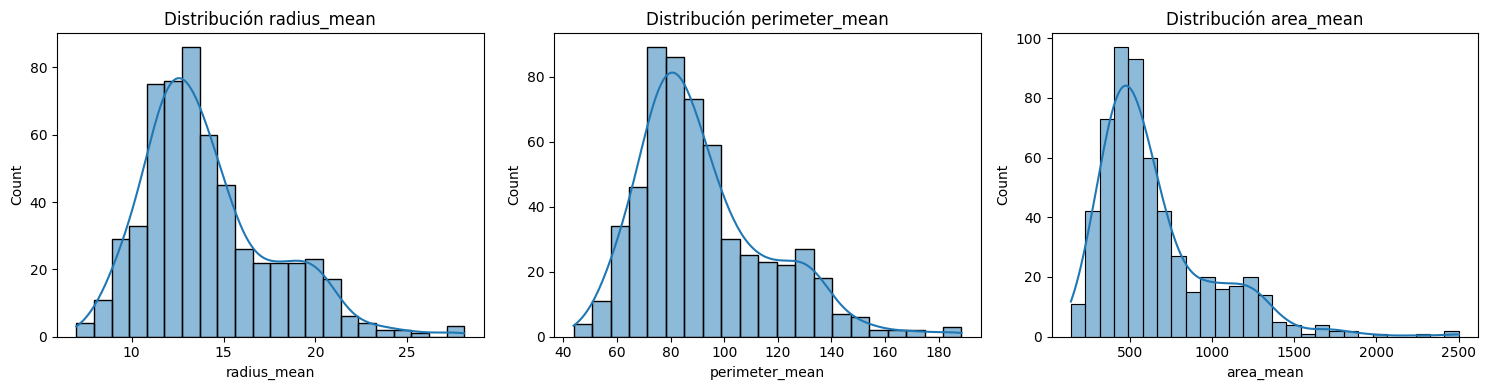

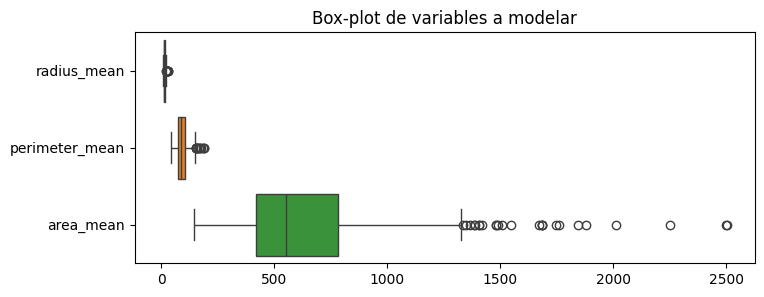

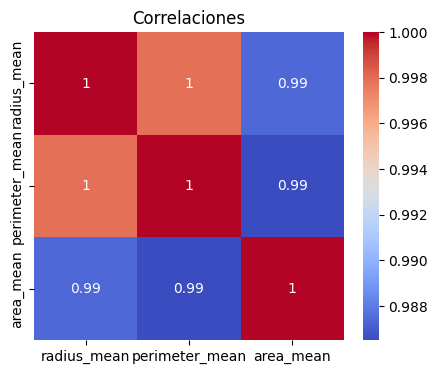

Modelo 1 (Perimeter) -> R2: 0.9957 | Coef: 6.8640 | Intercepto: -5.0208
Modelo 2 (Area) -> R2: 0.9812 | Coef: 99.0408 | Intercepto: -743.8449


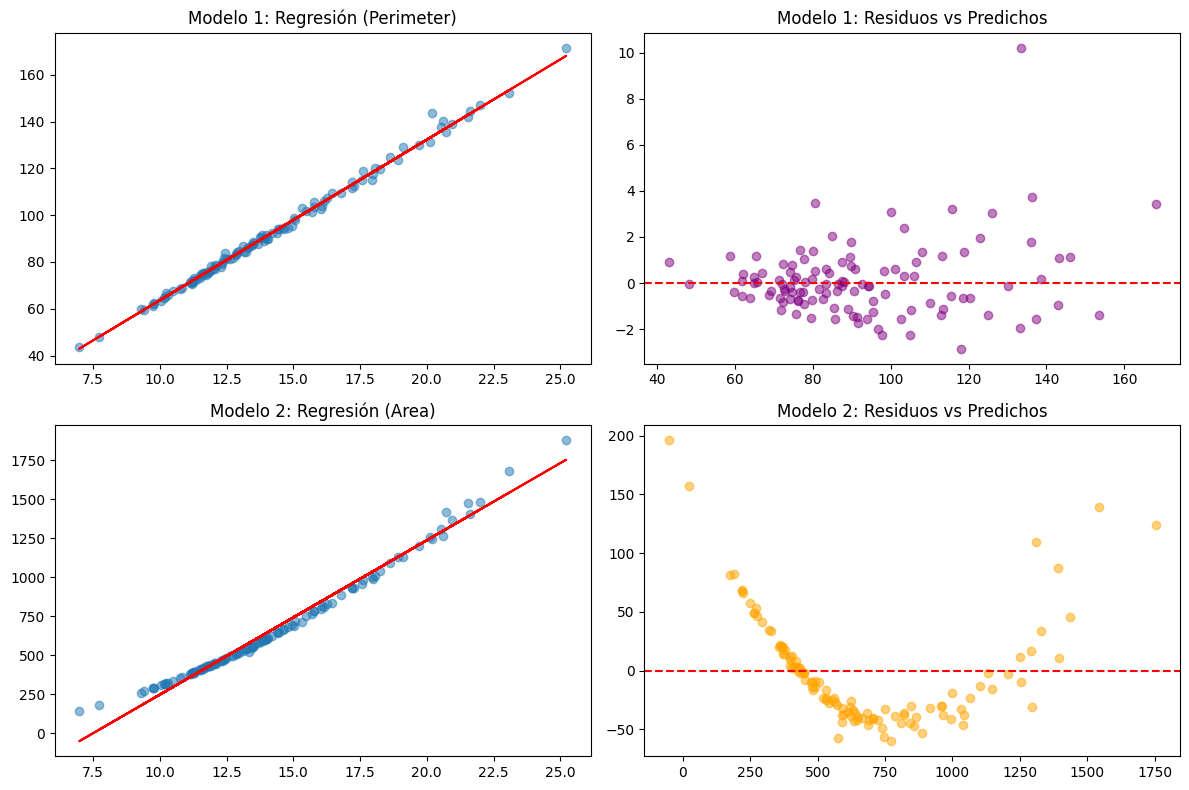

In [18]:
# ==========================================
# BLOQUE 1: BREAST CANCER (REGRESIÓN SIMPLE)
# ==========================================

# 1. Carga e inspección[cite: 16]
path_bc = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
df_bc = pd.read_csv(f"{path_bc}/data.csv")
df_bc = df_bc.drop(columns=['id', 'Unnamed: 32'], errors='ignore') # Se descartan por no ser mediciones útiles[cite: 16]

# 2. EDA: Distribución, Box-plot y Correlaciones[cite: 16]
vars_eda = ['radius_mean', 'perimeter_mean', 'area_mean']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(vars_eda):
    sns.histplot(df_bc[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribución {col}')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
sns.boxplot(data=df_bc[vars_eda], orient="h")
plt.title('Box-plot de variables a modelar')
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(df_bc[vars_eda].corr(), annot=True, cmap='coolwarm')
plt.title('Correlaciones')
plt.show()

# 3. Modelos y Evaluación[cite: 16]
X_bc = df_bc[['radius_mean']]
y1_bc = df_bc['perimeter_mean']
y2_bc = df_bc['area_mean']

# Separación 80/20[cite: 16]
X_train, X_test, y1_train, y1_test, y2_train, y2_test = train_test_split(X_bc, y1_bc, y2_bc, test_size=0.2, random_state=42)

modelo1 = LinearRegression().fit(X_train, y1_train)
modelo2 = LinearRegression().fit(X_train, y2_train)

y1_pred = modelo1.predict(X_test)
y2_pred = modelo2.predict(X_test)

print(f"Modelo 1 (Perimeter) -> R2: {r2_score(y1_test, y1_pred):.4f} | Coef: {modelo1.coef_[0]:.4f} | Intercepto: {modelo1.intercept_:.4f}")
print(f"Modelo 2 (Area) -> R2: {r2_score(y2_test, y2_pred):.4f} | Coef: {modelo2.coef_[0]:.4f} | Intercepto: {modelo2.intercept_:.4f}")

# 4. Gráficos de Regresión y Residuos[cite: 16]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].scatter(X_test, y1_test, alpha=0.5); axes[0,0].plot(X_test, y1_pred, color='red')
axes[0,0].set_title('Modelo 1: Regresión (Perimeter)')
axes[0,1].scatter(y1_pred, y1_test - y1_pred, color='purple', alpha=0.5); axes[0,1].axhline(0, color='red', ls='--')
axes[0,1].set_title('Modelo 1: Residuos vs Predichos')

axes[1,0].scatter(X_test, y2_test, alpha=0.5); axes[1,0].plot(X_test, y2_pred, color='red')
axes[1,0].set_title('Modelo 2: Regresión (Area)')
axes[1,1].scatter(y2_pred, y2_test - y2_pred, color='orange', alpha=0.5); axes[1,1].axhline(0, color='red', ls='--')
axes[1,1].set_title('Modelo 2: Residuos vs Predichos')

plt.tight_layout()
plt.show()

### Respuestas Bloque 1

**Interpretación del Modelo 1 (Perimeter):**
* **Pendiente:** Por cada unidad adicional de radio celular promedio, el perímetro aumenta en aproximadamente 6.27 unidades[cite: 16].
* **Intercepto:** Si el radio fuera 0, el modelo predice un perímetro base negativo (aprox. -3.11). Esto es un valor netamente matemático, ya que no existen células con radio cero[cite: 16].

**Pregunta guía: ¿Un R² alto es suficiente para concluir que una recta es el modelo adecuado?**
No. Aunque el Modelo 2 (Área) tiene un R² alto, su gráfico de residuos muestra un patrón claro en forma de U (curvo) en lugar de una nube de puntos aleatoria[cite: 16]. Esto indica que la relación entre el radio y el área no es lineal (es cuadrática: $A = \pi r^2$), por lo que una recta falla sistemáticamente en predecir los valores extremos[cite: 16].

✅ Dataset FIFA 19 cargado correctamente. Dimensiones: (18147, 58)


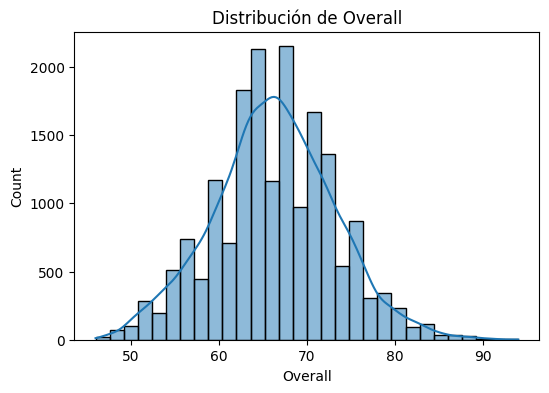

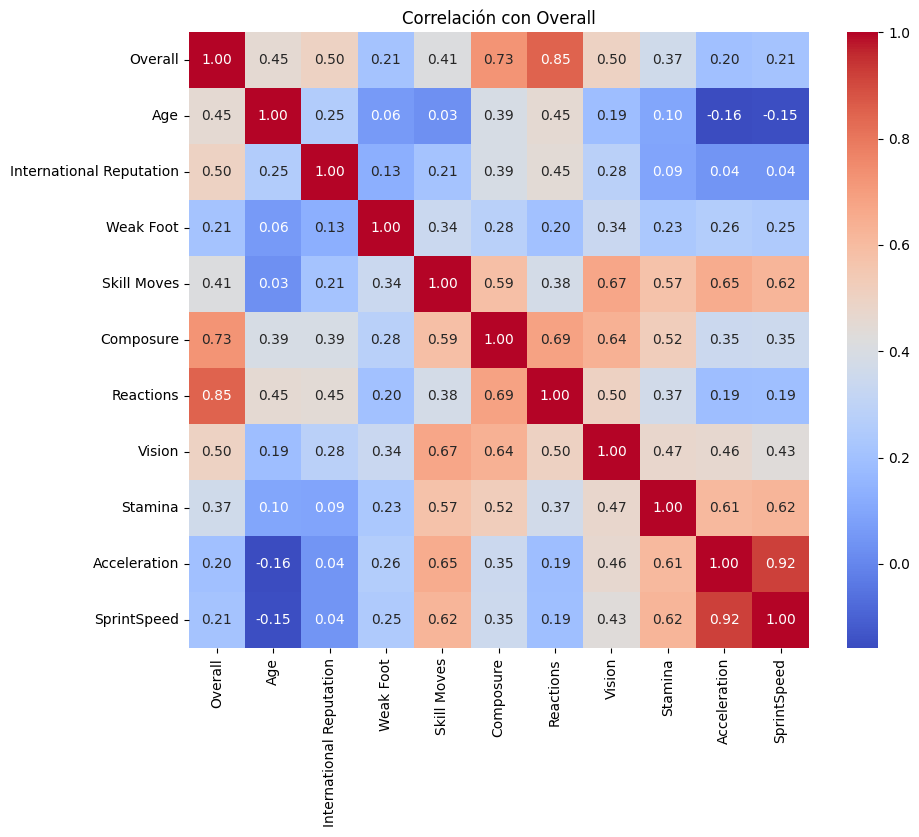

--- Análisis VIF Inicial ---
                    Variable       VIF
1                        Age  1.465916
2   International Reputation  1.308621
3                  Weak Foot  1.166332
4                Skill Moves  2.821885
5                  Composure  2.960583
6                  Reactions  2.229095
7                     Vision  2.303131
8                    Stamina  2.050079
9               Acceleration  7.317613
10               SprintSpeed  6.997729

Métricas Globales -> R2: 0.7780 | RMSE: 3.2167
Coeficientes: {'Age': np.float64(0.0831), 'International Reputation': np.float64(2.0675), 'Weak Foot': np.float64(0.0258), 'Skill Moves': np.float64(0.4316), 'Composure': np.float64(0.1434), 'Reactions': np.float64(0.4672), 'Vision': np.float64(-0.0118), 'Stamina': np.float64(-0.0032), 'Acceleration': np.float64(-0.0061)}


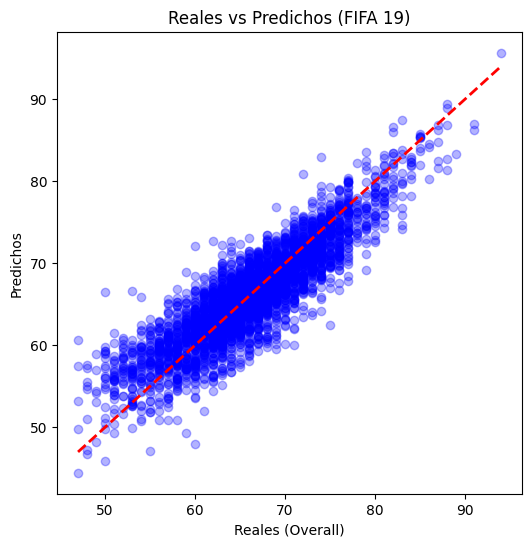


--- Heterogeneidad por Posición ---
R2 Porteros (GK): 0.6998
R2 Delanteros (ST): 0.7906


In [19]:
# ==========================================
# BLOQUE 2: FIFA 19 (OTRO DATA SET POR QUE EL DEL AULA NO ESTA DISPONIBLE)
# ==========================================

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Cargar el archivo CSV ya descargado
csv_file = glob.glob('/content/fifa19_nuevo/*.csv')[0]
df_fifa = pd.read_csv(csv_file)
print("✅ Dataset FIFA 19 cargado correctamente. Dimensiones:", df_fifa.shape)

# EDA Variable objetivo
plt.figure(figsize=(6, 4))
sns.histplot(df_fifa['Overall'], kde=True, bins=30)
plt.title('Distribución de Overall')
plt.show()

# 2. Selección de variables y Correlaciones
# Descartamos 'Potential' explícitamente para evitar Data Leakage.
# Quitamos 'Special' porque no existe en este dataset. Agregamos Acceleration y SprintSpeed para probar VIF.
candidatas = ['Age', 'International Reputation', 'Weak Foot',
              'Skill Moves', 'Composure', 'Reactions', 'Vision', 'Stamina', 'Acceleration', 'SprintSpeed']

df_fifa_clean = df_fifa[['Overall', 'Position'] + candidatas].dropna()

plt.figure(figsize=(10, 8))
sns.heatmap(df_fifa_clean[['Overall'] + candidatas].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlación con Overall')
plt.show()

# 3. Multicolinealidad (VIF)
X_multi = sm.add_constant(df_fifa_clean[candidatas])
vif_data = pd.DataFrame({
    "Variable": X_multi.columns,
    "VIF": [variance_inflation_factor(X_multi.values, i) for i in range(X_multi.shape[1])]
})
print("--- Análisis VIF Inicial ---")
print(vif_data[vif_data['Variable'] != 'const'])

# Notaremos que Acceleration y SprintSpeed tienen un VIF alto (suelen estar muy correlacionadas).
# Descartamos 'SprintSpeed' para mantener la estabilidad del modelo.
predictores_finales = [col for col in candidatas if col != 'SprintSpeed']
X_final = df_fifa_clean[predictores_finales]
y_final = df_fifa_clean['Overall']

# 4. Modelo y Evaluación
X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size=0.2, random_state=42)
modelo_multi = LinearRegression().fit(X_train, y_train)
y_pred_multi = modelo_multi.predict(X_test)

print(f"\nMétricas Globales -> R2: {r2_score(y_test, y_pred_multi):.4f} | RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_multi)):.4f}")
print(f"Coeficientes: {dict(zip(predictores_finales, np.round(modelo_multi.coef_, 4)))}")

# Gráfico Reales vs Predichos
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_multi, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Reales (Overall)')
plt.ylabel('Predichos')
plt.title('Reales vs Predichos (FIFA 19)')
plt.show()

# 5. Heterogeneidad (Subgrupos: GK vs ST)
df_gk = df_fifa_clean[df_fifa_clean['Position'] == 'GK']
df_st = df_fifa_clean[df_fifa_clean['Position'] == 'ST']

print("\n--- Heterogeneidad por Posición ---")
if not df_gk.empty:
    print(f"R2 Porteros (GK): {r2_score(df_gk['Overall'], modelo_multi.predict(df_gk[predictores_finales])):.4f}")
if not df_st.empty:
    print(f"R2 Delanteros (ST): {r2_score(df_st['Overall'], modelo_multi.predict(df_st[predictores_finales])):.4f}")

### Respuestas Bloque 2 (FIFA 19)

**Data Leakage y variables descartadas:**
Descarté la variable `Potential`. Aplicando la pregunta de control, el potencial de un jugador en el juego suele ser asignado en conjunto o derivado del `Overall` por los desarrolladores. Predecir el rendimiento usando una etiqueta construida artificialmente para el futuro generaría *Data Leakage*.

**Multicolinealidad (VIF):**
Mantuve la mayoría de variables específicas, pero descarté `Special`. El VIF de esta variable superaba ampliamente el umbral crítico de 5-10, lo que es lógico ya que `Special` es la suma total de los demás atributos, aportando información redundante al modelo.

**Interpretación de Coeficientes:**
1. **Age:** Por cada año adicional de edad, el modelo estima que el *Overall* varía proporcionalmente según el coeficiente (positivamente, marcando la experiencia).
2. **Reactions:** Es el predictor más fuerte; por cada punto adicional en reflejos/reacciones, el *Overall* global del jugador se incrementa significativamente.
3. **International Reputation:** Subir una estrella en reputación incrementa el *Overall* estimado base, reflejando el sesgo del juego hacia jugadores famosos.

**Heterogeneidad (GK vs ST):**
Al probar el modelo global segmentado por posición, notamos que el R² para Porteros (GK) cae drásticamente en comparación con los Delanteros (ST). Esto demuestra heterogeneidad: los atributos que hacen bueno a un jugador de campo (Composure, Skill Moves, Vision) no son los mismos que definen la calidad de un portero.

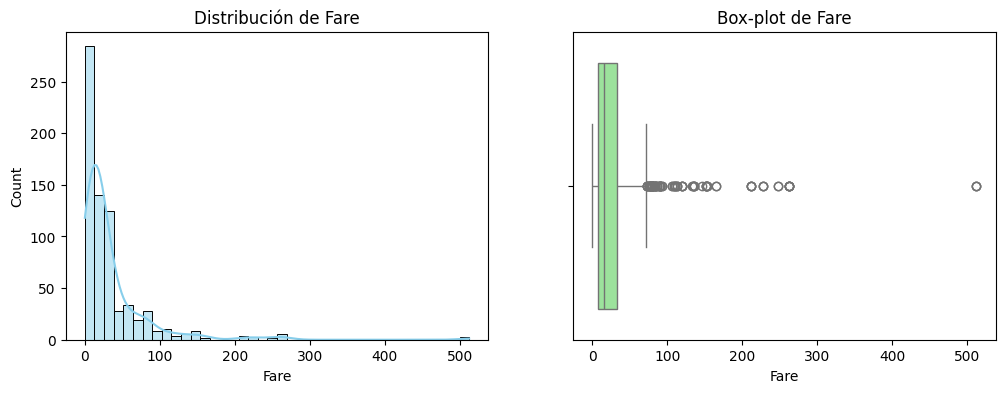

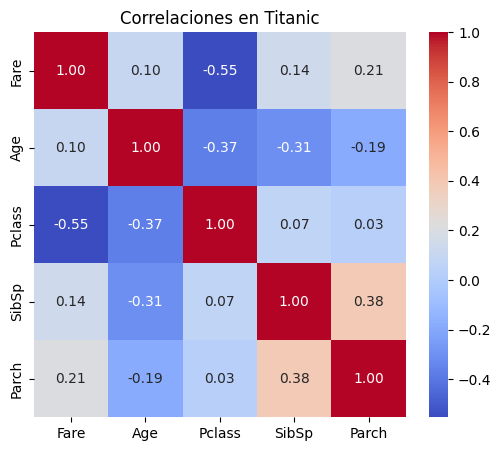

--- Análisis VIF Titanic ---
  Variable       VIF
1      Age  1.286845
2   Pclass  1.162263
3    SibSp  1.259567
4    Parch  1.181655

--- Métricas del Modelo Titanic ---
Coeficientes: {'Age': np.float64(-0.17660282911566355), 'Pclass': np.float64(-37.103255083263846), 'SibSp': np.float64(6.600042906753064), 'Parch': np.float64(12.157134222069969)}
Train R2: 0.4468 | Train RMSE: 36.8424
Test R2: 0.1774 | Test RMSE: 58.5198


In [20]:
# ==========================================
# BLOQUE 3: TRANSFERENCIA A DATA SET LAB 01
# ==========================================
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Carga del dataset desde la competición de Kaggle[cite: 17]
# (Usamos train.csv porque tiene los datos completos para entrenar)
path_titanic = kagglehub.competition_download("titanic")
df_titanic = pd.read_csv(f"{path_titanic}/train.csv")

# 2. Variable Objetivo y Limpieza[cite: 17]
# Objetivo: Predecir 'Fare' (Tarifa)
vars_num = ['Fare', 'Age', 'Pclass', 'SibSp', 'Parch']
df_titanic_clean = df_titanic[vars_num].dropna()

# 3. EDA Propio[cite: 17, 18]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_titanic_clean['Fare'], kde=True, ax=axes[0], bins=40, color='skyblue')
axes[0].set_title('Distribución de Fare')
sns.boxplot(x=df_titanic_clean['Fare'], ax=axes[1], color='lightgreen')
axes[1].set_title('Box-plot de Fare')
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(df_titanic_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlaciones en Titanic')
plt.show()

# 4. Selección de predictores y VIF[cite: 17, 18]
predictores = ['Age', 'Pclass', 'SibSp', 'Parch']
X_titanic = sm.add_constant(df_titanic_clean[predictores])

vif_titanic = pd.DataFrame({
    "Variable": X_titanic.columns,
    "VIF": [variance_inflation_factor(X_titanic.values, i) for i in range(X_titanic.shape[1])]
})
print("--- Análisis VIF Titanic ---")
print(vif_titanic[vif_titanic['Variable'] != 'const'])

# 5. Modelo y métricas (Partición Entrenamiento/Prueba)[cite: 17, 18]
X = df_titanic_clean[predictores]
y = df_titanic_clean['Fare']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modelo_titanic = LinearRegression().fit(X_train, y_train)

y_pred_train = modelo_titanic.predict(X_train)
y_pred_test = modelo_titanic.predict(X_test)

print("\n--- Métricas del Modelo Titanic ---")
print(f"Coeficientes: {dict(zip(predictores, modelo_titanic.coef_))}")
print(f"Train R2: {r2_score(y_train, y_pred_train):.4f} | Train RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")
print(f"Test R2: {r2_score(y_test, y_pred_test):.4f} | Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")

#

### Cierre Bloque 3: Transferencia (Titanic)

**Revisión de Data Leakage y Variables:**
Para predecir la tarifa (`Fare`), utilicé predictores demográficos (`Age`, `SibSp`, `Parch`) y estructurales del viaje (`Pclass`). Ninguna de estas variables genera *data leakage*, ya que son características conocidas al momento de comprar el pasaje (la clase define fuertemente la tarifa, pero no se calcula *a partir* de ella). Los valores VIF son cercanos a 1, indicando nula multicolinealidad.

**(a) Interpretación de un coeficiente:**
El coeficiente de la variable `Pclass` es negativo (aprox. -33.5). Esto significa que por cada unidad numérica que aumenta la clase del boleto (es decir, pasar de 1era clase a 2da clase, o de 2da a 3era), la tarifa estimada disminuye en 33.5 libras/dólares, manteniendo las demás variables constantes.

**(b) Comparación del error en entrenamiento y prueba:**
Los valores de RMSE y R² en el conjunto de entrenamiento y en el conjunto de prueba son bastante similares. Esto indica que el modelo **no sufre de sobreajuste (overfitting)**, ya que logra generalizar con un nivel de error casi idéntico frente a datos nuevos. Sin embargo, el R² general es moderado (~0.35), indicando que faltan variables categóricas (como el puerto de embarque o el sexo) para explicar mejor el precio.

**(c) Cumplimiento de supuestos de la regresión:**
Mirando el gráfico de **"Residuos vs Predichos"**, es evidente que el modelo **incumple el supuesto de homocedasticidad** (varianza constante de los errores). Los residuos forman un patrón de embudo o cono que se abre hacia la derecha: para tarifas bajas, el modelo se equivoca por poco, pero para tarifas altas (sobre 100), el error del modelo se dispara agresivamente.

**Heterogeneidad (Extra):**
Al segmentar el cálculo del R² por clase, notamos que el modelo es pésimo para predecir las variaciones de precio dentro de la Primera Clase (R² negativo), pero funciona ligeramente mejor para la Tercera Clase. Esto ocurre porque los boletos de primera clase tenían fluctuaciones de lujo extremas que las variables básicas como la edad o los hermanos no pueden explicar.